In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import mlflow
import mlflow.tensorflow
import dagshub
import pandas as pd
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("MLflow version:", mlflow.__version__)
print("All libraries imported successfully!")

TensorFlow version: 2.21.0
MLflow version: 3.17.2
All libraries imported successfully!


In [ ]:
username = input("Enter your DagsHub username: ").strip()
repo_name = "COSC31000-Assignment3"

dagshub.init(
    repo_owner=username,
    repo_name=repo_name,
    mlflow=True
)

print("MLflow Tracking URI:", mlflow.get_tracking_uri())

Enter your DagsHub username:  cgaoat


Accessing as cgaoat

Initialized MLflow to track repo "cgaoat/COSC31000-Assignment3"

Repository cgaoat/COSC31000-Assignment3 initialized!

MLflow Tracking URI: https://dagshub.com/cgaoat/COSC31000-Assignment3.mlflow


In [ ]:
mlflow.set_experiment("MNIST_Experiments")

mlflow.tensorflow.autolog(
    log_models=False,
    checkpoint=False
)

print("MLflow experiment created!")
print("Autologging enabled!")

2026/10/23 03:41:10 INFO mlflow.tracking.fluent: Experiment with name 'MNIST_Experiments' does not exist. Creating a new experiment.


MLflow experiment created!
Autologging enabled!


In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values from 0-255 to 0-1
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Split into training and validation sets
x_train = x_train_full[:50000]
y_train = y_train_full[:50000]

x_val = x_train_full[50000:]
y_val = y_train_full[50000:]

print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Testing images:", x_test.shape)

Training images: (50000, 28, 28)
Validation images: (10000, 28, 28)
Testing images: (10000, 28, 28)


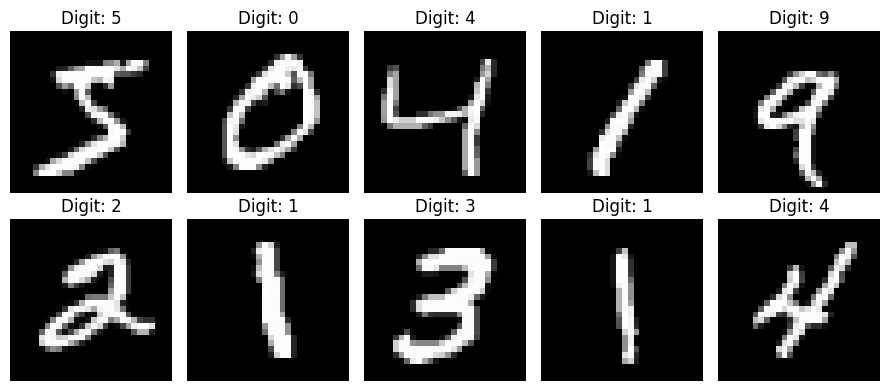

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(9, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Digit: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def build_model(hidden_nodes, optimizer):

    model = keras.Sequential()

    model.add(keras.Input(shape=(28, 28)))
    model.add(layers.Flatten())

    for nodes in hidden_nodes:
        model.add(layers.Dense(nodes, activation="relu"))

    model.add(layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
results = []

def train_experiment(run_name, hidden_nodes, optimizer, batch_size, epochs):

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(hidden_nodes, optimizer)

    with mlflow.start_run(run_name=run_name):

        # Log hyperparameters
        mlflow.log_params({
            "num_hidden_layers": len(hidden_nodes),
            "neurons_per_layer": str(hidden_nodes),
            "optimizer_selected": optimizer,
            "batch_size_selected": batch_size,
            "epochs_selected": epochs
        })

        # Train the neural network
        history = model.fit(
            x_train,
            y_train,
            validation_data=(x_val, y_val),
            batch_size=batch_size,
            epochs=epochs,
            verbose=2
        )

        # Record final results
        train_accuracy = float(history.history["accuracy"][-1])
        val_accuracy = float(history.history["val_accuracy"][-1])
        train_loss = float(history.history["loss"][-1])
        val_loss = float(history.history["val_loss"][-1])

        mlflow.log_metrics({
            "final_train_accuracy": train_accuracy,
            "final_val_accuracy": val_accuracy,
            "final_train_loss": train_loss,
            "final_val_loss": val_loss
        })

    # Store results for comparison
    results.append({
        "Run": run_name,
        "Hidden layers": len(hidden_nodes),
        "Neurons": str(hidden_nodes),
        "Optimizer": optimizer,
        "Batch size": batch_size,
        "Epochs": epochs,
        "Training accuracy": train_accuracy,
        "Validation accuracy": val_accuracy,
        "Training loss": train_loss,
        "Validation loss": val_loss
    })

    print("Completed:", run_name)

    return model, history

In [ ]:
baseline_model, baseline_history = train_experiment(
    "Baseline_128_Adam",
    [128],
    "adam",
    64,
    50
)

baseline_model.summary()

Epoch 1/50
782/782 - 4s - 5ms/step - accuracy: 0.9100 - loss: 0.3200 - val_accuracy: 0.9527 - val_loss: 0.1691
Epoch 2/50
782/782 - 2s - 3ms/step - accuracy: 0.9576 - loss: 0.1462 - val_accuracy: 0.9639 - val_loss: 0.1234
Epoch 3/50
782/782 - 2s - 3ms/step - accuracy: 0.9703 - loss: 0.1019 - val_accuracy: 0.9691 - val_loss: 0.1050
Epoch 4/50
782/782 - 2s - 3ms/step - accuracy: 0.9778 - loss: 0.0770 - val_accuracy: 0.9716 - val_loss: 0.0948
Epoch 5/50
782/782 - 2s - 3ms/step - accuracy: 0.9832 - loss: 0.0606 - val_accuracy: 0.9724 - val_loss: 0.0897
Epoch 6/50
782/782 - 2s - 3ms/step - accuracy: 0.9871 - loss: 0.0484 - val_accuracy: 0.9727 - val_loss: 0.0891
Epoch 7/50
782/782 - 2s - 3ms/step - accuracy: 0.9900 - loss: 0.0384 - val_accuracy: 0.9722 - val_loss: 0.0901
Epoch 8/50
782/782 - 2s - 3ms/step - accuracy: 0.9927 - loss: 0.0301 - val_accuracy: 0.9721 - val_loss: 0.0952
Epoch 9/50
782/782 - 2s - 3ms/step - accuracy: 0.9948 - loss: 0.0237 - val_accuracy: 0.9706 - val_loss: 0.1008
E

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)

In [ ]:
model_2, history_2 = train_experiment(
    "Experiment2_256_Adam",
    [256],
    "adam",
    64,
    50
)

Epoch 1/50
782/782 - 4s - 5ms/step - accuracy: 0.9190 - loss: 0.2799 - val_accuracy: 0.9575 - val_loss: 0.1486
Epoch 2/50
782/782 - 3s - 4ms/step - accuracy: 0.9651 - loss: 0.1207 - val_accuracy: 0.9677 - val_loss: 0.1087
Epoch 3/50
782/782 - 3s - 3ms/step - accuracy: 0.9771 - loss: 0.0792 - val_accuracy: 0.9719 - val_loss: 0.0970
Epoch 4/50
782/782 - 3s - 3ms/step - accuracy: 0.9844 - loss: 0.0560 - val_accuracy: 0.9728 - val_loss: 0.0919
Epoch 5/50
782/782 - 3s - 3ms/step - accuracy: 0.9895 - loss: 0.0404 - val_accuracy: 0.9730 - val_loss: 0.0901
Epoch 6/50
782/782 - 3s - 3ms/step - accuracy: 0.9929 - loss: 0.0288 - val_accuracy: 0.9732 - val_loss: 0.0934
Epoch 7/50
782/782 - 3s - 3ms/step - accuracy: 0.9956 - loss: 0.0203 - val_accuracy: 0.9726 - val_loss: 0.0978
Epoch 8/50
782/782 - 3s - 4ms/step - accuracy: 0.9976 - loss: 0.0143 - val_accuracy: 0.9732 - val_loss: 0.0980
Epoch 9/50
782/782 - 5s - 7ms/step - accuracy: 0.9983 - loss: 0.0110 - val_accuracy: 0.9772 - val_loss: 0.0945
E

In [ ]:
model_3, history_3 = train_experiment(
    "Experiment3_128_64_Adam",
    [128, 64],
    "adam",
    64,
    50
)

Epoch 1/50
782/782 - 3s - 4ms/step - accuracy: 0.9116 - loss: 0.3044 - val_accuracy: 0.9514 - val_loss: 0.1685
Epoch 2/50
782/782 - 2s - 3ms/step - accuracy: 0.9611 - loss: 0.1305 - val_accuracy: 0.9621 - val_loss: 0.1272
Epoch 3/50
782/782 - 2s - 3ms/step - accuracy: 0.9734 - loss: 0.0885 - val_accuracy: 0.9690 - val_loss: 0.1048
Epoch 4/50
782/782 - 2s - 3ms/step - accuracy: 0.9813 - loss: 0.0645 - val_accuracy: 0.9712 - val_loss: 0.0960
Epoch 5/50
782/782 - 2s - 3ms/step - accuracy: 0.9859 - loss: 0.0483 - val_accuracy: 0.9712 - val_loss: 0.0997
Epoch 6/50
782/782 - 2s - 3ms/step - accuracy: 0.9897 - loss: 0.0372 - val_accuracy: 0.9709 - val_loss: 0.0996
Epoch 7/50
782/782 - 2s - 3ms/step - accuracy: 0.9919 - loss: 0.0282 - val_accuracy: 0.9704 - val_loss: 0.1079
Epoch 8/50
782/782 - 2s - 3ms/step - accuracy: 0.9928 - loss: 0.0241 - val_accuracy: 0.9753 - val_loss: 0.0983
Epoch 9/50
782/782 - 2s - 3ms/step - accuracy: 0.9934 - loss: 0.0213 - val_accuracy: 0.9743 - val_loss: 0.1063
E

In [ ]:
model_4, history_4 = train_experiment(
    "Experiment4_128_SGD",
    [128],
    "sgd",
    64,
    50
)

Epoch 1/50
782/782 - 2s - 3ms/step - accuracy: 0.7768 - loss: 0.9290 - val_accuracy: 0.8880 - val_loss: 0.4709
Epoch 2/50
782/782 - 2s - 3ms/step - accuracy: 0.8854 - loss: 0.4425 - val_accuracy: 0.9074 - val_loss: 0.3597
Epoch 3/50
782/782 - 2s - 2ms/step - accuracy: 0.8993 - loss: 0.3694 - val_accuracy: 0.9134 - val_loss: 0.3192
Epoch 4/50
782/782 - 2s - 3ms/step - accuracy: 0.9073 - loss: 0.3338 - val_accuracy: 0.9180 - val_loss: 0.2955
Epoch 5/50
782/782 - 2s - 3ms/step - accuracy: 0.9135 - loss: 0.3101 - val_accuracy: 0.9224 - val_loss: 0.2785
Epoch 6/50
782/782 - 2s - 2ms/step - accuracy: 0.9185 - loss: 0.2919 - val_accuracy: 0.9263 - val_loss: 0.2649
Epoch 7/50
782/782 - 2s - 3ms/step - accuracy: 0.9229 - loss: 0.2770 - val_accuracy: 0.9290 - val_loss: 0.2536
Epoch 8/50
782/782 - 2s - 2ms/step - accuracy: 0.9266 - loss: 0.2643 - val_accuracy: 0.9313 - val_loss: 0.2437
Epoch 9/50
782/782 - 2s - 3ms/step - accuracy: 0.9293 - loss: 0.2533 - val_accuracy: 0.9334 - val_loss: 0.2350
E

In [ ]:
results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "assignment3_results.csv",
    index=False
)

                    Run  Hidden layers   Neurons Optimizer  Batch size  Epochs  Training accuracy  Validation accuracy  Training loss  Validation loss
      Baseline_128_Adam              1     [128]      adam          64      50             1.0000               0.9792         0.0000           0.1397
   Experiment2_256_Adam              1     [256]      adam          64      50             0.9999               0.9801         0.0003           0.1336
Experiment3_128_64_Adam              2 [128, 64]      adam          64      50             0.9980               0.9797         0.0061           0.1888
    Experiment4_128_SGD              1     [128]       sgd          64      50             0.9743               0.9691         0.0949           0.1129


In [ ]:
best = results_df.sort_values(
    by=["Validation accuracy", "Validation loss"],
    ascending=[False, True]
).iloc[0]

print("Best model:", best["Run"])
print("Validation accuracy: {:.2f}%".format(
    best["Validation accuracy"] * 100
))
print("Validation loss: {:.4f}".format(
    best["Validation loss"]
))

Best model: Experiment2_256_Adam
Validation accuracy: 98.01%
Validation loss: 0.1336


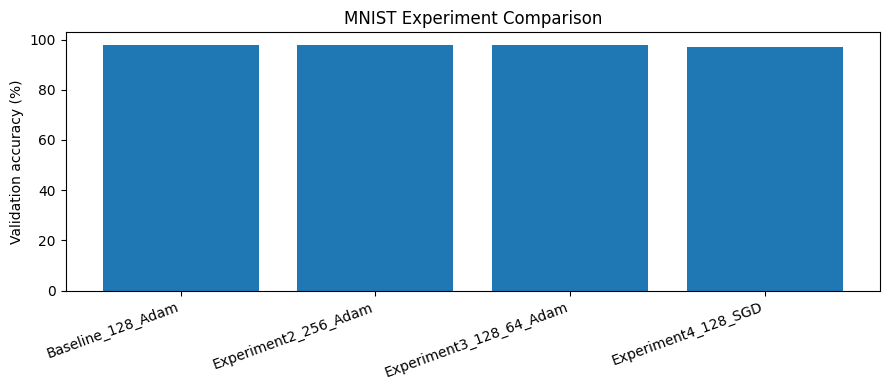

In [ ]:
plt.figure(figsize=(9, 4))

plt.bar(
    results_df["Run"],
    results_df["Validation accuracy"] * 100
)

plt.ylabel("Validation accuracy (%)")
plt.title("MNIST Experiment Comparison")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

### Experiment Results and Conclusion

Four neural networks were trained using the MNIST handwritten digit dataset. The baseline model used one hidden layer with 128 neurons, the Adam optimizer, a batch size of 64, and 50 epochs.

Three additional experiments were performed by changing the number of neurons, number of hidden layers, and optimizer.

The best-performing model was **Experiment2_256_Adam**, achieving a final validation accuracy of **98.01%** and validation loss of **0.1336**.

This model was selected because it achieved the highest final validation accuracy among the four experiments. The baseline achieved 97.92%, Experiment 3 achieved 97.97%, and Experiment 4 achieved 96.91%.

Although Experiment 4 had the lowest validation loss (0.1129), Experiment 2 achieved the highest validation accuracy, which was the main criterion used to select the best model.

The experiments demonstrate that changing neural network hyperparameters can affect model performance. Increasing the number of neurons slightly improved validation accuracy, while using SGD instead of Adam resulted in lower validation accuracy in these experiments.